# NIST Photovoltaic Data: Inspection, Feature Engineering and Fault Labeling

This notebook presents the methodology stage by stage for one selected Canopy or Ground dataset. It follows the structure of the original annual notebooks, using individual shared functions from `scripts/` for the calculations. Change the configuration to repeat the analysis across 2015–2018.

The compact `Site_Year_Labeling.ipynb` remains a separate batch runner. Here each transformation is followed by a report, table or plot so its effect can be examined and discussed in the diploma thesis. Findings are calculated when run; observations from one year are not assumed to hold for another.

## Notebook structure

1. Data Inspection
2. Feature Selection: secondary features, redundant features, faulty sensors, correlation
3. Feature Engineering: missing values, measurement bounds, operating mask
4. Expected vs Actual Power Analysis (Performance Ratio)
5. String Level Faults
6. Inverter Level Faults
7. Final validation, summaries and export

The three label families are rule-based supervision signals, not independently verified failure diagnoses. They remain separate for later analysis.


## Colab setup

Run in Google Colab, from top to bottom, after `Data_Overview.ipynb` has created the merged annual CSVs. The public repository supplies code only; datasets and exported results stay on Google Drive.

An existing checkout is reused within a runtime. Restart the runtime to clone updated code. When changing site/year, rerun from the configuration cell onward. Reapplying individual transformations to an already processed DataFrame may fail because columns were removed or features already exist.


In [ ]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/dulkusim/pv-timeseries-fault-forecasting.git"
repo_path = Path("/content/pv-timeseries-fault-forecasting")
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(repo_path)],
        check=True,
    )

labeling_dir = repo_path / "notebooks" / "Data Labeling"
if not (labeling_dir / "scripts" / "labeling.py").is_file():
    raise FileNotFoundError(f"Shared scripts not found in {labeling_dir}")
if str(labeling_dir) not in sys.path:
    sys.path.insert(0, str(labeling_dir))

import calendar
import json
from dataclasses import asdict
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Import each stage explicitly so its responsibility remains visible.
from scripts.config import CANOPY, GROUND, POA_MIN_OPERATING, POA_MIN_PR
from scripts.io import get_data_root, load_site_year, validate_site_year, save_stage
from scripts.feature_selection import (
    SECONDARY_FEATURES, REDUNDANT_FEATURES, CORRELATION_COLUMNS,
    drop_features, rtd_report, detect_faulty_rtds, drop_legacy_rtds,
    correlation_report,
)
from scripts.cleaning import missing_report, apply_missingness_policy
from scripts.operating import operating_mask, poa_fused, module_temp, pr_evaluable
from scripts.performance import expected_power, performance_features, label_power
from scripts.strings import (
    CURRENT_MIN, CURRENT_MAX, POWER_MIN, POWER_MAX,
    POA_MIN_STRING, STRING_REL_DEV_THRESHOLD, OPEN_CIRCUIT_RATIO,
    current_columns, power_columns, clean_string_bounds,
    string_aggregates, string_voltage_proxy, string_normalized,
    fit_string_baselines, apply_string_baselines, label_string,
)
from scripts.inverter import (
    FAULT_FLAG_COLUMNS, ORIGINAL_INVERTER_POLICY, REVISED_INVERTER_POLICY,
    inverter_features, label_inverter,
)
from scripts.labeling import summarize


## Google Drive and site configuration

`config.py` holds physical ratings, sensor selections, RTD removal choices and core circuits. Select `SITE_NAME` and `YEAR` below; the same notebook covers both sites and all four years.

Inputs come from `MyDrive/NIST_processed/`. Final CSVs go to `MyDrive/NIST_Labels/<site>_<year>.csv`.

Optional intermediate checkpoints use `io.save_stage` under `MyDrive/NIST_labeling_stages/`. They default to off to avoid several large CSV copies. That helper always rejects existing checkpoints; `OVERWRITE_FINAL` applies only to final exports.

The original inverter policy is selected explicitly to retain the annual notebooks' rules. The revised policy remains an option, explained in the inverter section.


In [ ]:
from google.colab import drive

drive.mount("/content/drive")
os.environ["DATA_ROOT"] = "/content/drive/MyDrive"
root = get_data_root()

SITE_NAME = "canopy" #other options: "ground"
YEAR = 2015 #other options: 2016, 2017, 2018
SAVE_CHECKPOINTS = False
OVERWRITE_FINAL = False
INVERTER_POLICY = REVISED_INVERTER_POLICY

sites = {"canopy": CANOPY, "ground": GROUND}
if SITE_NAME not in sites or YEAR not in (2015, 2016, 2017, 2018):
    raise ValueError("Choose canopy/ground and a year from 2015 through 2018")
site = sites[SITE_NAME]

output_dir = root / "NIST_Labels"
final_path = output_dir / f"{site.name}_{YEAR}.csv"
summary_path = output_dir / f"{site.name}_{YEAR}_label_summary.csv"
audit_path = output_dir / f"{site.name}_{YEAR}_stage_audit.csv"
metadata_path = output_dir / f"{site.name}_{YEAR}_methodology.json"
print(f"Selected dataset: {site.name}, {YEAR}")
display(pd.Series(asdict(site), name="configuration").to_frame())
print(f"Inverter policy: {INVERTER_POLICY}")


Mounted at /content/drive
Selected dataset: canopy, 2015


,configuration
name,canopy
p_rated_dc_kw,243.0
p_ac_max_kw,260.0
gamma,-0.00485
t_stc,25.0
n_strings,7
core_strings,"(2, 3, 4, 5, 6)"
op_mask_columns,"(Pyra1_Wm2_Avg, Pyra3_Wm2_Avg)"
op_mask_agg,max
poa_columns,"(RefCell1_Wm2_Avg, RefCell2_Wm2_Avg)"


Inverter policy: InverterPolicy(shutdown_column='InvPDC_kW_Avg', shutdown_threshold=1.0, invalid_status_above_five=True, efficiency_min_dc_kw=5.0, fault_flags_nonzero=True)


## Reporting utilities

The reporting functions are defined in the shared `scripts/reporting.py` module, keeping their implementations outside the notebook. This cell imports them and initializes the stage audit for the selected site/year.

`append_features` checks timestamp alignment and duplicate feature names. `report_stage` records dataset dimensions and optionally saves a checkpoint. `label_distribution` shows counts and percentages of all observations.

The notebook supplies its configuration to `report_stage` once using `partial`; the script does not depend on notebook global variables. Only a single working DataFrame is retained between stages, although calculations can still need substantial temporary Colab memory.


In [ ]:
from functools import partial
from scripts.reporting import append_features, label_distribution, report_stage as record_stage

stage_records = []

# Bind the current run's reporting settings; later stages use report_stage directly.
report_stage = partial(
    record_stage,
    records=stage_records,
    site=site,
    year=YEAR,
    save_checkpoints=SAVE_CHECKPOINTS,
)


# Data Inspection

The merged CSV is loaded through `load_site_year`. This helper parses `TIMESTAMP`, sets it as the index, sorts observations chronologically and rejects empty datasets, missing timestamps or observations from the wrong year. This prevents accidental reuse of another year's file.

Inspect records, types, ranges, shape and memory usage before removing features. Times retain their recorded local standard time; no timezone conversion is introduced.


In [12]:
# Load the original merged measurements; no engineered features are expected yet.
df = load_site_year(site, YEAR)
original_rows = len(df)
original_index = df.index.copy()
report_stage("Raw measurements", df)
display(df.head())


Raw measurements: 525,600 rows x 101 columns


,Pyra1_Wm2_Avg,Pyra2_Wm2_Avg,Pyra3_Wm2_Avg,RECORD,CR1000Temp_C_Avg,DoorOpen_Min,RefCell1_Wm2_Avg,RefCell2_Wm2_Avg,AmbTemp_C_Avg,InvVDVoltage_V_Avg,...,RTD_C_Avg_1,RTD_C_Avg_2,RTD_C_Avg_3,RTD_C_Avg_4,RTD_C_Avg_5,RTD_C_Avg_6,RTD_C_Avg_7,RTD_C_Avg_8,RTD_C_Avg_9,RTD_C_Avg_10
TIMESTAMP,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00-05:00,-4.433096,-8.782201,-4.542599,173899.0,-3.470,0.0,-0.548,-0.040,-2.229,11.75,...,-8.62,-8.29,-8.68,-8.48,-8.310,-8.66,-8.67,-8.100,-7.542,1.635
2015-01-01 00:01:00-05:00,-4.433096,-8.782201,-4.542599,173900.0,-3.476,0.0,-0.548,-0.040,-2.099,11.69,...,-8.61,-8.35,-8.52,-8.18,-8.020,-8.47,-8.40,-7.988,-7.385,1.635
2015-01-01 00:02:00-05:00,-4.433096,-8.782201,-4.542599,173901.0,-3.493,0.0,-0.550,-0.041,-2.185,11.62,...,-8.63,-8.39,-8.47,-8.14,-7.813,-8.38,-8.27,-7.973,-7.366,1.618
2015-01-01 00:03:00-05:00,-4.433096,-8.977362,-4.542599,173902.0,-3.493,0.0,-0.547,-0.038,-2.261,11.57,...,-8.61,-8.45,-8.45,-8.10,-7.831,-8.38,-8.25,-7.941,-7.367,1.618
2015-01-01 00:04:00-05:00,-4.669528,-9.270102,-4.542599,173903.0,-3.507,0.0,-0.545,-0.036,-2.391,11.49,...,-8.56,-8.45,-8.55,-8.07,-7.799,-8.38,-8.25,-7.973,-7.449,1.539


In [13]:
# Feature types, nonmissing counts and memory usage.
df.info()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 525600 entries, 2015-01-01 00:00:00-05:00 to 2015-12-31 23:59:00-05:00
Columns: 101 entries, Pyra1_Wm2_Avg to RTD_C_Avg_10
dtypes: float64(101)
memory usage: 409.0 MB


In [14]:
# Summary statistics for the original measurements.
df.describe()


,Pyra1_Wm2_Avg,Pyra2_Wm2_Avg,Pyra3_Wm2_Avg,RECORD,CR1000Temp_C_Avg,DoorOpen_Min,RefCell1_Wm2_Avg,RefCell2_Wm2_Avg,AmbTemp_C_Avg,InvVDVoltage_V_Avg,...,RTD_C_Avg_1,RTD_C_Avg_2,RTD_C_Avg_3,RTD_C_Avg_4,RTD_C_Avg_5,RTD_C_Avg_6,RTD_C_Avg_7,RTD_C_Avg_8,RTD_C_Avg_9,RTD_C_Avg_10
count,525235.000000,525235.000000,525235.000000,525235.000000,525235.000000,525235.000000,525235.000000,525235.000000,525235.000000,525235.000000,...,525235.000000,525235.000000,525235.000000,525235.000000,525235.000000,525234.000000,525235.000000,525235.000000,525235.000000,525235.000000
mean,167.429285,160.167997,168.245299,205021.662555,17.473426,0.026702,161.326398,159.277743,13.744469,192.028275,...,16.697201,17.016565,16.370072,16.671378,16.130982,16.680692,-27.761905,16.771227,16.252387,23.998807
std,270.211489,268.332786,271.639032,110432.411666,12.386112,2.609290,256.743640,254.657250,10.628394,166.904965,...,15.398464,15.701015,15.731751,15.521012,14.985293,15.698146,62.395839,15.497054,14.954201,14.479788
min,-12.944641,-20.686964,-9.141280,0.000000,-15.570000,0.000000,-0.581000,-0.254000,-17.010000,0.075000,...,-20.060000,-20.770000,-21.170000,-20.020000,-20.260000,-18.530000,-148.500000,-20.700000,-19.830000,-15.160000
25%,-3.960233,-8.489461,-3.869622,119560.500000,8.360000,0.000000,-0.304000,-0.125000,5.900000,8.590000,...,5.368000,5.562000,4.907000,5.315500,5.192000,5.150000,-98.600000,5.465000,5.368000,13.150000
50%,-0.413756,-4.586261,-0.168245,212384.000000,17.930000,0.000000,3.543000,1.734000,14.830000,308.600000,...,15.760000,15.980000,15.180000,15.590000,15.290000,15.490000,0.328000,15.720000,15.420000,24.480000
75%,253.868640,239.363780,253.993010,280290.500000,25.750000,0.000000,238.700000,234.000000,22.380000,347.000000,...,24.650000,24.970000,24.120000,24.490000,23.990000,24.560000,18.350000,24.590000,24.100000,34.450000
max,1429.171000,1418.813500,1436.751200,411599.000000,48.240000,255.000000,1385.000000,1391.000000,35.980000,469.700000,...,64.300000,67.730000,64.590000,63.870000,61.880000,64.060000,65.680000,64.210000,63.090000,58.280000


In [15]:
# Number of observations and measurement columns.
df.shape


(525600, 101)

In [16]:
# Total number of measurement cells.
df.size


53085600

## Dataset Column Descriptions

| Measurement group | Columns | Meaning |
|---|---|---|
| Time and logging | TIMESTAMP, RECORD, CR1000Temp_C_Avg | Recorded time, record number and logger temperature |
| Irradiance | Pyra*_Wm2_Avg, RefCell*_Wm2_Avg | Pyranometer/reference-cell irradiance (W/m²); sensor choice depends on site |
| Temperature | AmbTemp_C_Avg, RTD_C_Avg_1–9, RTD_C_Avg_10 | Ambient, module backsheet and inverter interior temperatures (°C) |
| Inverter power | InvPAC_kW_Avg, InvPDC_kW_Avg, InvEtot_kWh_Max | AC/DC power (kW) and cumulative energy (kWh) |
| Inverter electrical measurements | InvVa/b/c_Avg, InvIa/b/c_Avg, InvVDCin_Avg, InvIDCin_Avg, InvVPVin_Avg, InvVDVoltage_V_Avg, InvFreq_Avg | Phase measurements, DC voltages/current and frequency |
| Status and reported faults | InvOpStatus_Avg, Inv*Fault_Max, InvSystemWarn_Max, InvPVMStatus_Max | Operating status, fault/warning codes and monitoring status |
| Shunt-monitored circuits | ShuntCurrent_A_Avg_1–7, ShuntPDC_kW_Avg_1–7, ShuntEtot_kWh_Max_1–7 | Circuit current (A), power (kW) and cumulative energy (kWh) |
| Independent AC meter | PwrMtr* | Phase measurements, frequency, power, energy and distortion |
| Additional environment | SEWS*, Wind* | Integrator environmental sensors, wind measurements and diagnostics |
| DAS maintenance | DoorOpen_Min, Battery*, Load_A_Avg, Chg*, CkBatt_Max, Qloss_Ah_Max | Enclosure, battery and charging diagnostics |

The seven channels called “strings” in the scripts represent shunt-monitored output circuits/combiner boxes, rather than necessarily seven individual module strings. Their configured sensor roles are displayed below.


In [17]:
display(pd.DataFrame([
    {"purpose": "Operating mask", "columns": site.op_mask_columns, "aggregation": site.op_mask_agg},
    {"purpose": "Expected-power POA", "columns": site.poa_columns, "aggregation": site.poa_agg},
]))


,purpose,columns,aggregation
0,Operating mask,"(Pyra1_Wm2_Avg, Pyra3_Wm2_Avg)",max
1,Expected-power POA,"(RefCell1_Wm2_Avg, RefCell2_Wm2_Avg)",mean


## Timestamp Continuity and Annual Coverage

A complete one-minute year contains 525,600 observations, or 527,040 in a leap year. Compare annual and monthly row counts with these calendar expectations, and inspect unique timestamps, duplicates and steps that differ from one minute.

The recorded timezone is preserved. Continuity is calculated directly from consecutive timestamps without comparing them with a separate timezone-naive annual grid. Counts alone do not prove completeness: duplicates can compensate for missing observations, and counts do not establish the exact annual endpoints. The observed timestamp range is shown for that reason.

The scripts use row-based rolling windows. Five, fifteen and sixty rows represent those minute durations only under regular one-minute sampling. These diagnostics do not fill gaps or remove duplicates; irregularities should inform the later analysis.


In [18]:
# Use calendar counts for annual expectations and recorded timestamps for continuity.
expected_minutes = (366 if calendar.isleap(YEAR) else 365) * 24 * 60
time_steps = df.index.to_series().diff().dropna()
coverage = pd.Series({
    "expected_minutes": expected_minutes,
    "observed_rows": len(df),
    "unique_timestamps": df.index.nunique(),
    "duplicate_timestamps": int(df.index.duplicated().sum()),
    "steps_different_from_one_minute": int(time_steps.ne(pd.Timedelta(minutes=1)).sum()),
}, name="coverage")
display(coverage.to_frame())
print(f"Observed range: {df.index.min()} to {df.index.max()}")

monthly_rows = df.groupby(df.index.month).size().reindex(range(1, 13), fill_value=0)
monthly_expected = pd.Series({m: calendar.monthrange(YEAR, m)[1] * 24 * 60 for m in range(1, 13)})
display(pd.DataFrame({"observed_rows": monthly_rows, "expected_minutes": monthly_expected}))


,coverage
expected_minutes,525600
observed_rows,525600
unique_timestamps,525600
duplicate_timestamps,0
steps_different_from_one_minute,0


Observed range: 2015-01-01 00:00:00-05:00 to 2015-12-31 23:59:00-05:00


,observed_rows,expected_minutes
1,44640,44640
2,40320,40320
3,44640,44640
4,43200,43200
5,44640,44640
6,43200,43200
7,44640,44640
8,44640,44640
9,43200,43200
10,44640,44640


# Feature Selection

In this step, non-essential, redundant, and faulty features are removed from the dataset in order to improve data quality and reduce unnecessary complexity before further analysis and modeling.

### Secondary Feature Removal

The first group of removed columns includes:

- Datalogger and maintenance variables
- Battery and charging system measurements
- Sensor diagnostic signals
- Secondary wind-related measurements
- Cumulative per-string energy counters

These variables were excluded because they are not directly related to photovoltaic performance or fault behavior and contribute limited predictive value.

In [19]:
# Show the shared policy instead of repeating its list in every annual notebook.
display(pd.DataFrame({"secondary_feature_removed": SECONDARY_FEATURES}))
df = drop_features(df, groups=("secondary",))
report_stage("Secondary features removed", df)


,secondary_feature_removed
0,RECORD
1,CR1000Temp_C_Avg
2,DoorOpen_Min
3,Battery_V_Min
4,Battery_A_Avg
5,Load_A_Avg
6,ChgState_Min
7,ChgSource_Min
8,CkBatt_Max
9,Qloss_Ah_Max


Secondary features removed: 525,600 rows x 78 columns


### Redundant Feature Removal

Additional features were removed due to redundancy with more directly relevant inverter-side measurements.

These mainly include:

- Secondary power meter statistics
- Reactive power and reactive energy measurements
- Harmonic distortion measurements
- Redundant environmental measurements

The goal was to reduce feature overlap while retaining the core electrical and environmental signals most relevant to photovoltaic system behavior.

In [20]:
display(pd.DataFrame({"redundant_feature_removed": REDUNDANT_FEATURES}))
df = drop_features(df, groups=("redundant",))
report_stage("Redundant features removed", df)


,redundant_feature_removed
0,PwrMtrFreqMin_Min
1,PwrMtrFreqMax_Max
2,PwrMtrPhaseRev_Avg
3,PwrMtrP_kVAR_Avg
4,PwrMtrP_kVA_Avg
5,PwrMtrEdel_kWh_Max
6,PwrMtrErec_kWh_Max
7,PwrMtrEdel_kVARh_Max
8,PwrMtrErec_kVARh_Max
9,PwrMtrVaTHDMax_Max


Redundant features removed: 525,600 rows x 63 columns


## Faulty Sensor Detection

The nine module RTDs are inspected by comparing annual mean temperatures. `detect_faulty_rtds` flags sensors whose mean differs by more than 3 °C from the median sensor mean. This is a screening diagnostic: an unusual mean motivates inspection, while a plausible mean does not prove year-round reliability.

Removal follows the established site policy to preserve consistency across annual datasets:

- Canopy removes RTDs 3, 5, 6 and 7; later module temperature uses 1, 2, 4, 8 and 9.
- Ground removes RTDs 2, 3 and 8; later module temperature uses 1, 4, 5, 6, 7 and 9.

The table and plot provide evidence for the selected year. The diagnostic candidates do not automatically replace the configured removal policy.


,mean_c,diagnostic_candidate,removed_by_site_policy
RTD_C_Avg_1,16.697201,False,False
RTD_C_Avg_2,17.016565,False,False
RTD_C_Avg_3,16.370072,False,True
RTD_C_Avg_4,16.671378,False,False
RTD_C_Avg_5,16.130982,False,True
RTD_C_Avg_6,16.680692,False,True
RTD_C_Avg_7,-27.761905,True,True
RTD_C_Avg_8,16.771227,False,False
RTD_C_Avg_9,16.252387,False,False


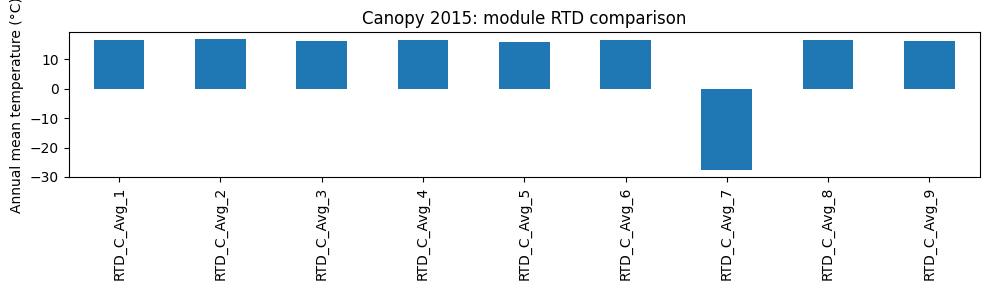

In [21]:
rtd_means = rtd_report(df)
suspect_rtds = detect_faulty_rtds(df, tol=10.0)
rtd_means["diagnostic_candidate"] = rtd_means.index.isin(suspect_rtds)
rtd_means["removed_by_site_policy"] = rtd_means.index.isin(
    [f"RTD_C_Avg_{i}" for i in site.rtd_drop]
)
display(rtd_means)
ax = rtd_means["mean_c"].plot.bar(
    figsize=(10, 3), ylabel="Annual mean temperature (°C)"
)
ax.set_title(f"{site.name.title()} {YEAR}: module RTD comparison")
plt.tight_layout()
plt.show()


In [22]:
# Retain the same module sensor set across years for this installation.
df = drop_legacy_rtds(df, site)
report_stage("Site-specific RTDs removed", df)


Site-specific RTDs removed: 525,600 rows x 59 columns


## Correlation Analysis for Feature Redundancy

A Pearson correlation matrix compares retained inverter and meter electrical measurements. Inverter/meter phase currents and AC power may capture overlapping behavior while still describing different measurement noise or grid-side effects.

`correlation_report` lists pairs with absolute correlation at least 0.9. The full matrix and heatmap are also shown. This is a diagnostic rather than an automatic elimination rule: these selected electrical columns remain available for labeling and later model-based selection. Discuss the calculated values rather than assuming the correlations match a previous year.


,InvVDVoltage_V_Avg,InvVa_Avg,InvVb_Avg,InvVc_Avg,InvIa_Avg,InvIb_Avg,InvIc_Avg,InvVDCin_Avg,InvIDCin_Avg,InvFreq_Avg,PwrMtrIa_Avg,PwrMtrIb_Avg,PwrMtrIc_Avg,PwrMtrFreq_Avg,PwrMtrVa_Avg,PwrMtrVb_Avg,PwrMtrVc_Avg,PwrMtrP_kW_Avg
InvVDVoltage_V_Avg,1.000,0.005,0.007,0.009,0.482,0.487,0.484,0.940,0.531,0.009,0.562,0.574,0.565,0.003,-0.274,-0.260,-0.226,0.546
InvVa_Avg,0.005,1.000,1.000,1.000,0.507,0.504,0.508,0.260,0.222,1.000,0.012,0.013,0.013,0.000,0.033,0.027,0.035,0.013
InvVb_Avg,0.007,1.000,1.000,1.000,0.510,0.508,0.511,0.263,0.226,1.000,0.016,0.016,0.016,0.000,0.030,0.027,0.033,0.016
InvVc_Avg,0.009,1.000,1.000,1.000,0.512,0.509,0.513,0.265,0.228,1.000,0.018,0.018,0.018,0.000,0.028,0.024,0.033,0.018
InvIa_Avg,0.482,0.507,0.510,0.512,1.000,1.000,1.000,0.608,0.950,0.508,0.867,0.867,0.867,0.003,-0.218,-0.196,-0.194,0.868
InvIb_Avg,0.487,0.504,0.508,0.509,1.000,1.000,1.000,0.612,0.951,0.506,0.868,0.869,0.868,0.003,-0.219,-0.197,-0.195,0.869
InvIc_Avg,0.484,0.508,0.511,0.513,1.000,1.000,1.000,0.610,0.950,0.509,0.867,0.867,0.866,0.003,-0.218,-0.196,-0.194,0.867
InvVDCin_Avg,0.940,0.260,0.263,0.265,0.608,0.612,0.610,1.000,0.584,0.264,0.561,0.573,0.563,0.002,-0.245,-0.228,-0.197,0.545
InvIDCin_Avg,0.531,0.222,0.226,0.228,0.950,0.951,0.950,0.584,1.000,0.224,0.974,0.973,0.974,0.004,-0.262,-0.231,-0.230,0.974
InvFreq_Avg,0.009,1.000,1.000,1.000,0.508,0.506,0.509,0.264,0.224,1.000,0.014,0.014,0.014,0.000,0.009,0.006,0.013,0.014


,feature_1,feature_2,correlation
0,InvIb_Avg,InvIc_Avg,0.999985
1,PwrMtrIa_Avg,PwrMtrIc_Avg,0.999975
2,InvIa_Avg,InvIc_Avg,0.999974
3,InvVb_Avg,InvVc_Avg,0.999960
4,InvIa_Avg,InvIb_Avg,0.999952
5,InvVa_Avg,InvVb_Avg,0.999933
6,InvVa_Avg,InvVc_Avg,0.999910
7,PwrMtrIa_Avg,PwrMtrIb_Avg,0.999841
8,PwrMtrIb_Avg,PwrMtrIc_Avg,0.999836
9,InvVc_Avg,InvFreq_Avg,0.999623


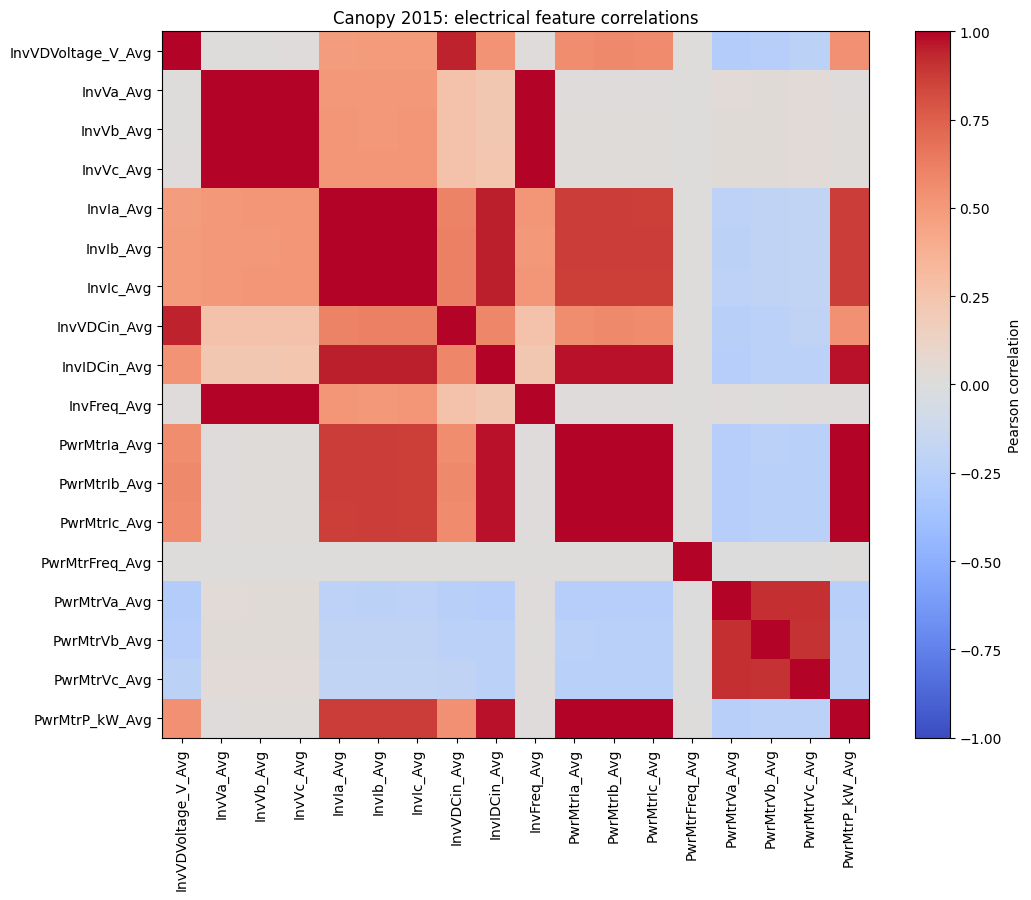

Feature selection complete: 525,600 rows x 59 columns


In [23]:
correlations = df.loc[:, list(CORRELATION_COLUMNS)].corr()
display(correlations.round(3))
display(correlation_report(df, threshold=0.9))

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlations)), correlations.columns, rotation=90)
ax.set_yticks(range(len(correlations)), correlations.index)
ax.set_title(f"{site.name.title()} {YEAR}: electrical feature correlations")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()
report_stage("Feature selection complete", df, checkpoint="features")


# Feature Engineering

## Missing Values

`missing_report` lists missing counts and fractions. The established cross-site policy removes `WindSpeedAve_ms`; it does **not** remove every column above a percentage threshold. Critical electrical measurements remain even when incomplete.

The `SEWS*` environmental columns were already removed in the redundant group. No general interpolation or row deletion is introduced. Subsequent masks and label precedence determine how incomplete observations are categorized; not every missing input results in a missing-data label.


In [ ]:
missing_before = missing_report(df)
display(missing_before.assign(missing_percent=100 * missing_before["missing_fraction"]))

# Preserve the shared column policy for both sites and all years.
df = apply_missingness_policy(df)

In [26]:
display(missing_report(df))
report_stage("Missingness policy applied", df)

,missing_count,missing_fraction
Pyra1_Wm2_Avg,365,0.000694
Pyra2_Wm2_Avg,365,0.000694
Pyra3_Wm2_Avg,365,0.000694
RefCell1_Wm2_Avg,365,0.000694
RefCell2_Wm2_Avg,365,0.000694
AmbTemp_C_Avg,365,0.000694
InvVDVoltage_V_Avg,365,0.000694
InvVa_Avg,365,0.000694
InvVb_Avg,365,0.000694
InvVc_Avg,365,0.000694


Missingness policy applied: 525,600 rows x 58 columns


## Physical Bounds for String Measurements

The shared pipeline replaces currents outside 0–150 A and powers outside 0–50 kW with missing values for each of the seven circuits. Rows are retained. The report distinguishes original missing values from measurements rejected by these bounds.

Cleaning occurs here before operating/performance features to match the shared pipeline order. Its effect is revisited in the string section.


In [28]:
string_current_cols = current_columns(site.n_strings)
string_power_cols = power_columns(site.n_strings)
string_measurements = string_current_cols + string_power_cols
bounds_report = pd.DataFrame({"missing_before": df[string_measurements].isna().sum()})
print(f"Allowed current: {CURRENT_MIN}–{CURRENT_MAX} A; power: {POWER_MIN}–{POWER_MAX} kW")
df = clean_string_bounds(df)
bounds_report["missing_after"] = df[string_measurements].isna().sum()
bounds_report["rejected_by_bounds"] = bounds_report["missing_after"] - bounds_report["missing_before"]
display(bounds_report)
report_stage("Bounds cleaning complete", df, checkpoint="cleaned")


Allowed current: 0.0–150.0 A; power: 0.0–50.0 kW


,missing_before,missing_after,rejected_by_bounds
ShuntCurrent_A_Avg_1,365,47385,47020
ShuntCurrent_A_Avg_2,365,64158,63793
ShuntCurrent_A_Avg_3,365,38911,38546
ShuntCurrent_A_Avg_4,365,22225,21860
ShuntCurrent_A_Avg_5,365,2746,2381
ShuntCurrent_A_Avg_6,365,5656,5291
ShuntCurrent_A_Avg_7,365,3997,3632
ShuntPDC_kW_Avg_1,365,1449,1084
ShuntPDC_kW_Avg_2,365,6819,6454
ShuntPDC_kW_Avg_3,365,5172,4807


Bounds cleaning complete: 525,600 rows x 58 columns


## Operating Mask Creation

`Op_Mask` distinguishes sufficient irradiance from low-irradiance/nighttime conditions:

- Canopy uses the maximum of `Pyra1_Wm2_Avg` and `Pyra3_Wm2_Avg` to account for the two orientations.
- Ground uses `Pyra2_Wm2_Avg` alone.

The mask equals 1 when the configured irradiance is **strictly greater than 100 W/m²**, and 0 otherwise. It describes expected operation from irradiance, not confirmation that the inverter is producing.

The helper follows pandas aggregation/comparison behavior for missing readings. In particular, a missing result fails the threshold comparison and becomes 0; missing irradiance is not separately labeled at this stage.


Operating irradiance threshold: > 100.0 W/m²


,count,percent_of_all_rows
Op_Mask,,
0,335254,63.785008
1,190346,36.214992


Operating observations: 190,346 (36.21% of rows)
Equivalent sampled hours at one-minute spacing: 3,172.43


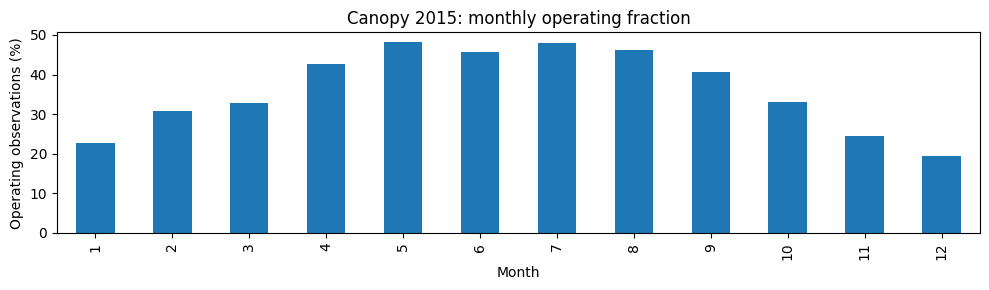

Operating mask created: 525,600 rows x 59 columns


In [29]:
df["Op_Mask"] = operating_mask(df, site)
print(f"Operating irradiance threshold: > {POA_MIN_OPERATING} W/m²")
display(label_distribution(df["Op_Mask"]))

operating_rows = int(df["Op_Mask"].sum())
print(f"Operating observations: {operating_rows:,} ({100 * operating_rows / len(df):.2f}% of rows)")
print(f"Equivalent sampled hours at one-minute spacing: {operating_rows / 60:,.2f}")
ax = df["Op_Mask"].groupby(df.index.month).mean().mul(100).plot.bar(
    figsize=(10, 3), ylabel="Operating observations (%)", xlabel="Month"
)
ax.set_title(f"{site.name.title()} {YEAR}: monthly operating fraction")
plt.tight_layout()
plt.show()
report_stage("Operating mask created", df, checkpoint="operating")


# Expected vs Actual Power Analysis (Performance Ratio)

Physics-based features compare measured inverter AC output with an irradiance- and temperature-based power reference. Inputs are site DC rating, reference-cell POA, retained module RTDs, temperature coefficient and inverter AC ceiling.

This is the project's reference model, not a full simulation of all conversion/environmental losses. The ratio thresholds provide heuristic supervision and do not independently establish a particular physical fault.

## POA Irradiance, Module Temperature and PR Evaluation Mask

Canopy `POA_fused` is the **mean** of the two reference cells; Ground uses `RefCell1_Wm2_Avg`. This differs from the pyranometer maximum used for Canopy's operating mask. Module temperature is the row-wise median of configured retained RTDs.

`PR_evaluable` requires operating mask 1, POA at least 200 W/m² and inverter status strictly above 0 and at most 5. The higher irradiance threshold reduces sensitivity to ratios at weak illumination. Missing module temperature or AC output is handled later by the power label function rather than this mask.


In [30]:
# Keep POA fusion and module RTD selection specific to the chosen site.
df["POA_fused"] = poa_fused(df, site)
df["module_temp"] = module_temp(df, site)
df["PR_evaluable"] = pr_evaluable(df, site)
print(f"PR irradiance threshold: >= {POA_MIN_PR} W/m²")
display(df[["POA_fused", "module_temp"]].describe().T)
display(label_distribution(df["PR_evaluable"]))
display(pd.crosstab(df["Op_Mask"], df["PR_evaluable"], margins=True))


PR irradiance threshold: >= 200.0 W/m²


,count,mean,std,min,25%,50%,75%,max
POA_fused,525235.0,160.302071,254.789821,-0.37,-0.2095,2.6445,237.45,1386.00
module_temp,525235.0,16.714858,15.467464,-20.02,5.4190,15.6900,24.58,63.84


,count,percent_of_all_rows
PR_evaluable,,
0,382385,72.752093
1,143215,27.247907


PR_evaluable,0,1,All
Op_Mask,,,
0,335254,0,335254
1,47131,143215,190346
All,382385,143215,525600


## Temperature-Corrected Expected Power

The expected DC reference is

$$P_{expected,DC}=P_{rated,DC}\frac{G_{POA}}{1000}\left[1+\gamma(T_{module}-T_{STC})\right].$$

Configuration uses 243 kW DC for Canopy, 271 kW DC for Ground, $\gamma=-0.00485$ per °C and $T_{STC}=25$ °C. The AC reference is capped at the 260 kW inverter ceiling:

$$P_{expected,AC}=\min(P_{expected,DC},P_{AC,max}).$$

The cap limits the reference when DC potential exceeds inverter capacity; it does not explicitly estimate conversion efficiency. The helper applies an upper cap only and preserves the remaining calculated values, including missing values.


In [31]:
df = append_features(df, expected_power(df, site))
display(df[["InvPAC_kW_Avg", "P_expected_DC_kW", "P_expected_AC_kW"]].describe().T)


,count,mean,std,min,25%,50%,75%,max
InvPAC_kW_Avg,525235.0,32.799417,67.622524,-999.000000,0.000000,0.000000,50.840000,260.000000
P_expected_DC_kW,525235.0,37.187691,57.249235,-0.097013,-0.054061,0.683735,58.118917,309.682393
P_expected_AC_kW,525235.0,37.186519,57.244472,-0.097013,-0.054061,0.683735,58.118917,260.000000


## Performance Ratio and Energy-Weighted Rolling Features

Instantaneous PR is $P_{actual,AC}/P_{expected,AC}$, with zero reference power replaced by a missing denominator. The weighted rolling ratio uses evaluable observations:

$$PR_{weighted,w}=\frac{\sum_w P_{actual,AC}}{\sum_w P_{expected,AC}}.$$

This ratio of sums reduces the influence of low-power observations compared with an unweighted mean of individual ratios. The helper produces 5-, 15- and 60-row windows with at least 3, 8 and 30 valid observations respectively. These represent minute windows under regular one-minute sampling.

The 15-row ratio drives labels. Other windows, instantaneous PR, rolling standard deviation (15 rows, minimum 8) and power deficit (expected minus actual) provide diagnostic/model features. The standard deviation uses instantaneous PR without the evaluability mask, matching the script.

Selected power/performance columns are rounded to three decimals **after calculation and before labeling**, as in the shared pipeline. This can affect threshold-adjacent observations.


In [32]:
df = append_features(df, performance_features(df))
round_columns = [
    "module_temp", "P_expected_DC_kW", "P_expected_AC_kW", "PR",
    "PR_roll_5min_weighted", "PR_roll_15min_weighted", "PR_roll_60min_weighted",
    "PR_roll_std_15min", "power_deficit_kW",
]
df[round_columns] = df[round_columns].round(3)
display(df.loc[df["PR_evaluable"].eq(1), round_columns].describe().T)


,count,mean,std,min,25%,50%,75%,max
module_temp,143215.0,32.784093,14.879931,-12.710,22.6300,34.500,44.3900,63.840
P_expected_DC_kW,143215.0,119.817460,47.134542,42.634,78.3815,114.415,158.8425,309.682
P_expected_AC_kW,143215.0,119.813159,47.120865,42.634,78.3815,114.415,158.8425,260.000
PR,143215.0,0.937005,0.171349,0.000,0.9610,0.979,0.9910,1.844
PR_roll_5min_weighted,140604.0,0.936749,0.170045,0.000,0.9610,0.979,0.9900,1.776
PR_roll_15min_weighted,137772.0,0.937315,0.168675,0.000,0.9620,0.978,0.9890,1.620
PR_roll_60min_weighted,130790.0,0.939143,0.167259,0.000,0.9640,0.978,0.9880,1.098
PR_roll_std_15min,143208.0,0.017137,0.115772,0.000,0.0020,0.006,0.0180,12.180
power_deficit_kW,143215.0,7.532023,23.243494,-60.111,0.9980,2.080,4.7140,240.786


## Expected vs Actual Power: Visual Inspection

Daily means expose annual variation without drawing every minute. They include all observations and are descriptive averages, not daily energy totals. Gaps can affect their interpretation.

A selected day shows one-minute power and PR. The first day with a PR-evaluable observation is chosen automatically; change `PLOT_DAY` to inspect an event. If no observations are PR-evaluable, the first recorded day is shown.


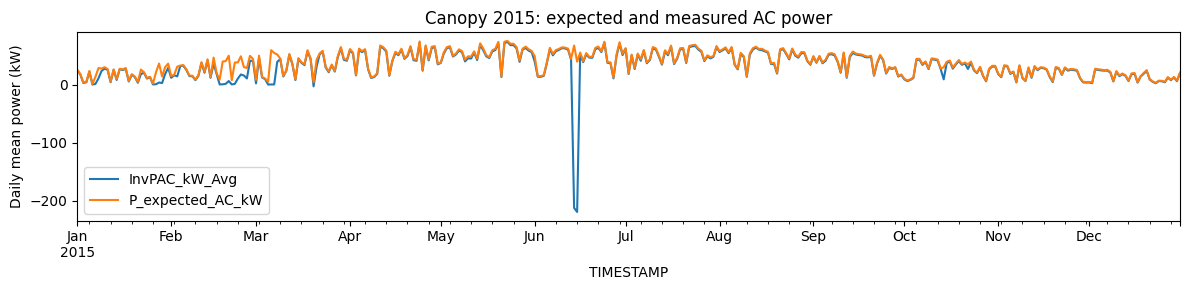

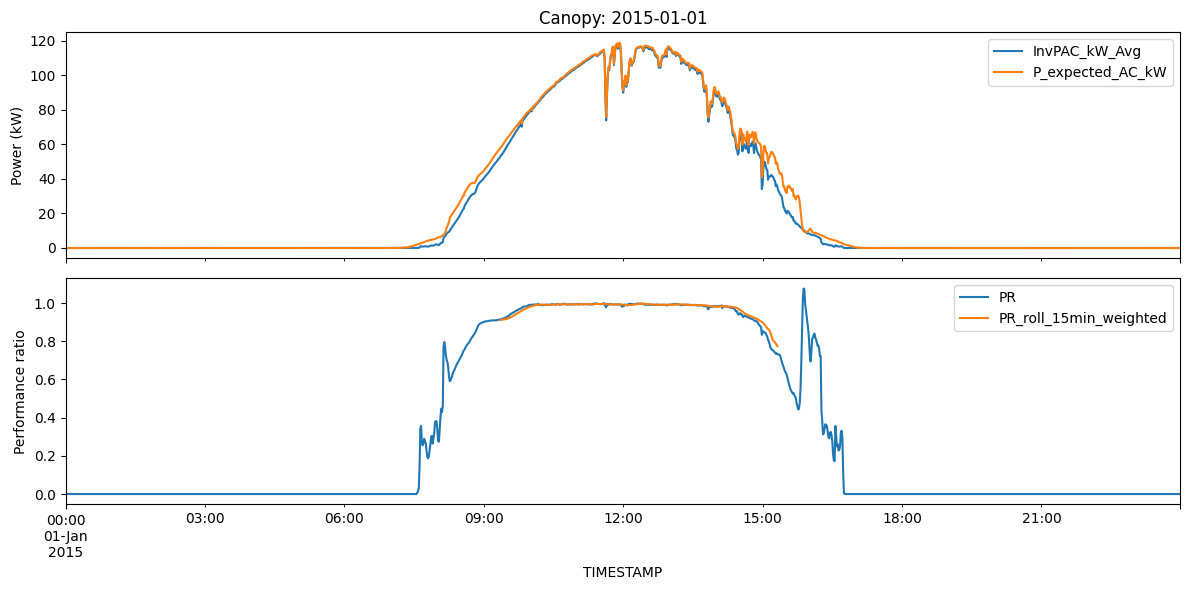

In [33]:
fig, ax = plt.subplots(figsize=(12, 3))
df[["InvPAC_kW_Avg", "P_expected_AC_kW"]].resample("D").mean().plot(ax=ax)
ax.set(ylabel="Daily mean power (kW)", title=f"{site.name.title()} {YEAR}: expected and measured AC power")
plt.tight_layout()
plt.show()

evaluable_times = df.index[df["PR_evaluable"].eq(1)]
PLOT_DAY = (evaluable_times[0] if len(evaluable_times) else df.index[0]).strftime("%Y-%m-%d")
day = df.loc[PLOT_DAY, ["InvPAC_kW_Avg", "P_expected_AC_kW", "PR", "PR_roll_15min_weighted"]]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
day[["InvPAC_kW_Avg", "P_expected_AC_kW"]].plot(ax=axes[0])
axes[0].set(ylabel="Power (kW)", title=f"{site.name.title()}: {PLOT_DAY}")
day[["PR", "PR_roll_15min_weighted"]].plot(ax=axes[1])
axes[1].set_ylabel("Performance ratio")
plt.tight_layout()
plt.show()


## Physics-Based Fault Labeling

`label_power` evaluates these conditions in order; the **first matching condition wins**.

| Priority | Label | Rule |
|---|---|---|
| 1 | NOT_EVALUABLE | PR_evaluable = 0 |
| 2 | MISSING_DATA | Expected/measured AC power missing, or 15-row weighted PR missing for an evaluable observation |
| 3 | CRITICAL_UNDERPERFORMANCE | Evaluable and $0 \le PR_{15} < 0.50$ |
| 4 | SEVERE_UNDERPERFORMANCE | Evaluable and $0.50 \le PR_{15} < 0.70$ |
| 5 | UNDERPERFORMANCE | Evaluable and $0.70 \le PR_{15} < 0.85$ |
| 6 | SUSPICIOUSLY_HIGH | Evaluable and $PR_{15} > 1.05$ |
| 7 | NEGATIVE_AC_POWER | Evaluable and instantaneous AC power negative, if no earlier condition matched |
| Default | NORMAL | No preceding condition matched |

The bands distinguish degrees of departure from the reference. They can motivate inspection for shading, soiling, electrical problems or measurement disagreement, but do not uniquely identify those causes. The normal PR band includes both 0.85 and 1.05 when no other rule takes precedence.

Precedence matters: missing status/irradiance can make an observation non-evaluable before missing-data checks. Negative instantaneous power does not override an earlier PR category.


,count,percent_of_all_rows
label_power,,
NOT_EVALUABLE,382385,72.752093
NORMAL,129373,24.614346
CRITICAL_UNDERPERFORMANCE,5448,1.036530
MISSING_DATA,5443,1.035578
UNDERPERFORMANCE,2170,0.412861
SEVERE_UNDERPERFORMANCE,658,0.125190
SUSPICIOUSLY_HIGH,123,0.023402


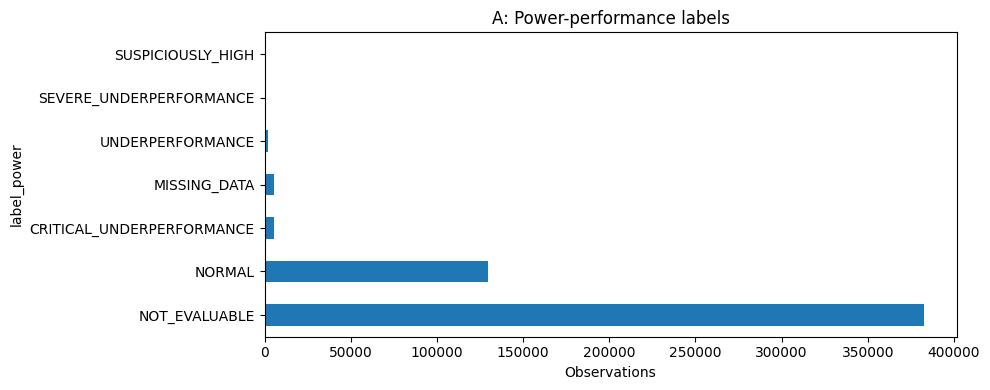

Performance features and power labels: 525,600 rows x 71 columns


In [34]:
# A: Power-performance labels from the shared rules.
df["label_power"] = label_power(df, missing_label="MISSING_DATA")
display(label_distribution(df["label_power"]))
ax = df["label_power"].value_counts().plot.barh(figsize=(10, 4), xlabel="Observations")
ax.set_title("A: Power-performance labels")
plt.tight_layout()
plt.show()
report_stage("Performance features and power labels", df, checkpoint="performance")


# String Level Faults

String analysis distinguishes disagreement between circuits from whole-system power loss. It uses the seven shunt current/power channels after bounds cleaning. The sequence follows the original notebooks: aggregates, per-circuit deviations, voltage proxies, irradiance normalization, individual baselines, rolling deviations and labels.

## 1. String Current and Power Aggregates

`string_aggregates` calculates current mean, standard deviation, minimum/maximum, coefficient of variation ($CV=\sigma/\mu$), range relative to mean and per-circuit standardized deviations. It also calculates power mean, standard deviation, total and CV, and a 5-row current-CV average with at least 3 observations.

Large spread indicates disagreement, but structural differences can cause persistent spread without faults. `P_string_total` uses pandas' default summation: partial missing channels produce a partial total, and an all-missing row sums to zero. This matters when interpreting the inverter DC discrepancy later.


In [35]:
# Inspect the earlier bounds-cleaning effect before deriving string features.
display(bounds_report)
display(df[string_measurements].describe().T)

df = append_features(df, string_aggregates(df))
aggregate_columns = [
    "I_string_mean", "I_string_std", "I_string_min", "I_string_max",
    "I_string_cv", "I_string_range_ratio", "I_string_cv_roll5",
    "P_string_mean", "P_string_std", "P_string_total", "P_string_cv",
]
display(df[aggregate_columns].describe().T)
display(df[[f"I_string_{i}_dev" for i in range(1, site.n_strings + 1)]].describe().T)


,missing_before,missing_after,rejected_by_bounds
ShuntCurrent_A_Avg_1,365,47385,47020
ShuntCurrent_A_Avg_2,365,64158,63793
ShuntCurrent_A_Avg_3,365,38911,38546
ShuntCurrent_A_Avg_4,365,22225,21860
ShuntCurrent_A_Avg_5,365,2746,2381
ShuntCurrent_A_Avg_6,365,5656,5291
ShuntCurrent_A_Avg_7,365,3997,3632
ShuntPDC_kW_Avg_1,365,1449,1084
ShuntPDC_kW_Avg_2,365,6819,6454
ShuntPDC_kW_Avg_3,365,5172,4807


,count,mean,std,min,25%,50%,75%,max
ShuntCurrent_A_Avg_1,478215.0,13.517025,20.802595,0.0,0.004,0.6390,20.540,98.80
ShuntCurrent_A_Avg_2,461442.0,19.486631,29.121427,0.0,0.005,1.1865,30.780,139.40
ShuntCurrent_A_Avg_3,486689.0,18.389129,28.586422,0.0,0.006,0.6510,27.810,138.00
ShuntCurrent_A_Avg_4,503375.0,17.977273,28.529028,0.0,0.006,0.4030,26.750,139.50
ShuntCurrent_A_Avg_5,522854.0,14.586663,23.941985,0.0,0.012,0.1100,20.860,118.30
ShuntCurrent_A_Avg_6,519944.0,14.643934,23.921981,0.0,0.008,0.1430,20.840,117.20
ShuntCurrent_A_Avg_7,521603.0,12.010960,19.932529,0.0,0.009,0.1180,16.370,99.40
ShuntPDC_kW_Avg_1,524151.0,4.161046,6.675962,0.0,0.000,0.0380,6.038,32.58
ShuntPDC_kW_Avg_2,518781.0,5.837231,9.255209,0.0,0.000,0.0590,8.780,44.16
ShuntPDC_kW_Avg_3,520428.0,5.791637,9.215659,0.0,0.000,0.0550,8.670,43.85


,count,mean,std,min,25%,50%,75%,max
I_string_mean,525076.0,14.957481,24.501199,0.000000,0.006286,0.132571,21.062857,121.514286
I_string_std,523733.0,2.557638,3.953290,0.000000,0.003359,0.025132,4.206614,39.766317
I_string_min,525076.0,10.969879,18.930536,0.000000,0.003000,0.080000,13.390000,98.800000
I_string_max,525076.0,17.594162,28.449920,0.000000,0.012000,0.172000,25.340000,139.500000
I_string_cv,523718.0,0.404110,0.312604,0.000000,0.151793,0.285628,0.555369,2.430987
I_string_range_ratio,525056.0,1.036374,0.771440,0.000000,0.393525,0.759036,1.452830,5.960651
I_string_cv_roll5,524210.0,0.404311,0.306777,0.092077,0.152011,0.287814,0.558229,2.000680
P_string_mean,525077.0,5.036989,8.059314,0.000000,0.000000,0.043714,7.465571,38.862857
P_string_std,524956.0,0.865923,1.318649,0.000000,0.000000,0.007721,1.464488,9.874440
P_string_total,525600.0,35.211847,56.395359,0.000000,0.000000,0.287000,52.117250,272.040000


,count,mean,std,min,25%,50%,75%,max
I_string_1_dev,478162.0,-1.002402,0.626515,-2.220951,-1.290416,-1.137147,-0.889043,2.260390
I_string_2_dev,461442.0,0.042312,0.917856,-2.085118,-0.956132,0.528886,0.931163,2.226792
I_string_3_dev,486687.0,0.160620,0.732820,-2.008316,-0.544705,0.250647,0.908753,1.994500
I_string_4_dev,503308.0,0.354329,0.707947,-2.034147,-0.297044,0.575477,0.982599,2.213697
I_string_5_dev,521617.0,0.600930,0.894188,-2.001232,-0.163106,0.146257,1.500000,2.215647
I_string_6_dev,519931.0,0.069457,0.466699,-2.118691,-0.226995,-0.001526,0.468807,1.924871
I_string_7_dev,521572.0,-0.280480,1.035916,-2.233002,-1.284146,-0.173749,0.694879,2.247118


## 2. Per-String Operating Voltage Proxies

For each circuit, `string_voltage_proxy` calculates $R_i=1000P_i/I_i$, converting kW to W. Despite its historical `R_string_*` name, this is a **voltage proxy in volts**, not resistance. Zero current becomes a missing denominator.

The helper adds fleet mean, standard deviation, CV and standardized per-circuit proxy deviations. These support inspection of voltage disagreement; they do not introduce a separate voltage-based label in the current string rules.


In [36]:
df = append_features(df, string_voltage_proxy(df))
R_cols = [f"R_string_{i}" for i in range(1, site.n_strings + 1)]
display(df[R_cols + ["R_string_mean", "R_string_std", "R_string_cv"]].describe().T)


,count,mean,std,min,25%,50%,75%,max
R_string_1,455657.0,212.051077,168.042692,0.0,0.000000,322.517972,349.175080,1000.000000
R_string_2,440945.0,214.959598,167.263412,0.0,0.000000,324.045085,349.476831,500.000000
R_string_3,470249.0,202.740699,169.726374,0.0,0.000000,318.950593,347.765957,500.000000
R_string_4,489585.0,198.224931,170.039338,0.0,0.000000,316.135266,347.202107,500.000000
R_string_5,522479.0,185.108037,170.493098,0.0,0.000000,306.478579,345.042173,1000.000000
R_string_6,514987.0,187.821274,171.039014,0.0,0.000000,309.529554,345.653940,1000.000000
R_string_7,518439.0,186.525408,171.038343,0.0,0.000000,308.380258,345.563584,1000.000000
R_string_mean,525056.0,185.489409,170.757554,0.0,0.000000,307.056814,345.379897,642.857143
R_string_std,521234.0,3.371424,17.578159,0.0,0.000000,0.051423,0.098258,396.862697
R_string_cv,292760.0,0.053923,0.259519,0.0,0.000191,0.000265,0.000728,2.645751


## 3. POA-Normalized Features

`string_normalized` calculates $I_{norm,i}=I_i/G_{POA}$ and $P_{norm,i}=P_i/G_{POA}$, replacing zero POA with a missing denominator. Normalization reduces irradiance-driven variation when comparing a circuit with its own history.

The helper also returns normalized-power standard deviation and CV across circuits. These features do not guarantee that temperature, shading and other effects have been eliminated.

The following diagnostics use operating mask 1, POA at least 200 W/m² and inverter status in (0, 5], matching the baseline/string evaluation criteria.


In [37]:
df = append_features(df, string_normalized(df))
evaluable_string = (
    df["Op_Mask"].eq(1)
    & df["POA_fused"].ge(POA_MIN_STRING)
    & df["InvOpStatus_Avg"].gt(0)
    & df["InvOpStatus_Avg"].le(5)
)
normalized_columns = [f"Inorm_string_{i}" for i in range(1, site.n_strings + 1)]
display(df.loc[evaluable_string, normalized_columns].describe().T)
display(df.loc[evaluable_string, ["Pnorm_string_std", "Pnorm_string_cv"]].describe().T)
display(df.loc[evaluable_string, R_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
Inorm_string_1,143177.0,0.076625,0.017155,0.000045,0.074294,0.079783,0.084191,0.182698
Inorm_string_2,143092.0,0.107272,0.019848,0.000049,0.109560,0.111245,0.113352,0.262177
Inorm_string_3,143064.0,0.106947,0.019563,0.000126,0.107330,0.110695,0.113943,0.277316
Inorm_string_4,143158.0,0.107993,0.019760,0.000034,0.110674,0.111917,0.113614,0.270189
Inorm_string_5,142964.0,0.091245,0.018246,0.000008,0.094273,0.095399,0.096372,0.225707
Inorm_string_6,142906.0,0.091153,0.017763,0.000002,0.091387,0.094866,0.097923,0.236274
Inorm_string_7,142967.0,0.073894,0.020197,0.000000,0.073363,0.078487,0.082845,0.197601


,count,mean,std,min,25%,50%,75%,max
Pnorm_string_std,143186.0,0.005670,0.001993,0.000029,0.004744,0.005131,0.005728,0.016950
Pnorm_string_cv,143186.0,0.189087,0.105468,0.054065,0.148187,0.152323,0.173385,2.163797


,count,mean,std,min,25%,50%,75%,max
R_string_1,143176.0,342.278487,24.864849,0.000000,323.347424,338.966247,358.618510,462.523423
R_string_2,143080.0,342.027697,24.464788,6.409639,323.317163,338.933680,358.387520,464.454976
R_string_3,143048.0,342.053055,24.628548,58.372978,323.300761,338.928040,358.453376,434.343434
R_string_4,143157.0,342.115073,24.532602,144.736842,323.305939,338.949172,358.550231,462.676963
R_string_5,142932.0,341.826258,24.685793,0.000000,323.244045,338.863415,358.292564,448.275862
R_string_6,142883.0,341.959565,24.680411,0.000000,323.269510,338.863001,358.257332,438.167939
R_string_7,142949.0,341.971485,24.884454,0.000000,323.203935,338.842975,358.365210,437.185930


## 4. Per-String Baseline Normalization

Raw fleet CV can reflect structural asymmetry between circuits. Instead, compare each circuit with its own characteristic irradiance response. `fit_string_baselines` takes the median normalized current over evaluable observations.

For baseline $b_i$, expected current and relative deviation are

$$I_{expected,i}=b_iG_{POA},\qquad d_i=\frac{I_i-I_{expected,i}}{I_{expected,i}}.$$

A negative deviation means lower current than this circuit's expectation; a positive deviation means higher current.

The annual median is a reference fingerprint, **not a baseline verified from healthy observations**. Persistent faults may affect it. This exploratory notebook fits the selected full year, matching the annual workflow; later forecasting evaluation should fit on training data only to prevent future-data leakage. The shared helper rejects nonfinite/nonpositive baselines.


In [38]:
INORM_BASELINE = fit_string_baselines(df, site)
baseline_report = pd.Series(
    INORM_BASELINE, name="baseline_A_m2_per_W"
).rename_axis("string").to_frame()
display(baseline_report)

df = append_features(df, apply_string_baselines(df, INORM_BASELINE))
rel_dev_cols = [f"I_string_{i}_rel_dev" for i in range(1, site.n_strings + 1)]
display(df.loc[evaluable_string, rel_dev_cols].describe(percentiles=[0.05, 0.5, 0.95]).T)


,baseline_A_m2_per_W
string,
1,0.079783
2,0.111245
3,0.110695
4,0.111917
5,0.095399
6,0.094866
7,0.078487


,count,mean,std,min,5%,50%,95%,max
I_string_1_rel_dev,143177.0,-0.039582,0.215021,-0.999431,-0.483624,0.000000e+00,0.215159,1.289946
I_string_2_rel_dev,143092.0,-0.035715,0.178420,-0.999562,-0.265153,-1.180065e-17,0.053192,1.356750
I_string_3_rel_dev,143064.0,-0.033856,0.176732,-0.998860,-0.205760,2.666936e-17,0.088645,1.505227
I_string_4_rel_dev,143158.0,-0.035061,0.176562,-0.999692,-0.187014,-4.868510e-17,0.040685,1.414185
I_string_5_rel_dev,142964.0,-0.043550,0.191258,-0.999917,-0.302269,-4.093279e-17,0.036707,1.365914
I_string_6_rel_dev,142906.0,-0.039136,0.187243,-0.999974,-0.361051,5.929961e-17,0.108808,1.490610
I_string_7_rel_dev,142967.0,-0.058517,0.257324,-1.000000,-0.770234,0.000000e+00,0.213333,1.517630


## 5. Rolling Deviations and String Fault Labels

`apply_string_baselines` produces maximum absolute relative deviation across all seven circuits, cross-circuit standard deviation and the 5-row rolling mean of the maximum (minimum 3 observations).

Ground uses all seven circuits for imbalance. For Canopy, the label helper recomputes the rolling maximum using core circuits **2–6**; channels 1 and 7 remain in engineered features and diagnostic tables. The open-circuit check uses minimum/mean current across **all seven** circuits for both sites.

`label_string` applies these ordered rules:

| Priority | Label | Rule |
|---|---|---|
| 1 | NOT_EVALUABLE | Outside the string evaluation mask |
| 2 | MISSING_DATA | Fleet mean current missing |
| 3 | OPEN_CIRCUIT_STRING | Minimum current < 10% of fleet mean during evaluable operation |
| 4 | STRING_IMBALANCE | No open circuit and the selected core-circuit rolling absolute-deviation metric > 20% |
| Default | NORMAL | No preceding condition matched |

Because the metric is absolute, imbalance can reflect positive or negative departures. A rolling average above threshold does **not** require five consecutive faulty minutes. Partial missing channels can be skipped by aggregates and are not necessarily assigned MISSING_DATA; that check tests the fleet mean.


In [40]:
# B: Pass configured core circuits explicitly to preserve site-specific decisions.
print(f"Core circuits for imbalance: {site.core_strings}")
print(f"Open-circuit ratio: {OPEN_CIRCUIT_RATIO}; imbalance threshold: {STRING_REL_DEV_THRESHOLD}")
df["label_string"] = label_string(df, core_strings=site.core_strings)
display(label_distribution(df["label_string"]))

# Display the actual imbalance metric used by this site's label function.
core_rel_dev_cols = [f"I_string_{i}_rel_dev" for i in site.core_strings]
if set(site.core_strings) == set(range(1, site.n_strings + 1)):
    imbalance_metric = df["I_rel_dev_max_roll5"]
else:
    imbalance_metric = df[core_rel_dev_cols].abs().max(axis=1).rolling(5, min_periods=3).mean()
display(imbalance_metric.loc[evaluable_string].describe().to_frame("label_imbalance_metric"))
report_stage("String features and labels", df, checkpoint="strings")


Core circuits for imbalance: (2, 3, 4, 5, 6)
Open-circuit ratio: 0.1; imbalance threshold: 0.2


,count,percent_of_all_rows
label_string,,
NOT_EVALUABLE,382385,72.752093
NORMAL,132049,25.123478
STRING_IMBALANCE,10871,2.068303
OPEN_CIRCUIT_STRING,276,0.052511
MISSING_DATA,19,0.003615


,label_imbalance_metric
count,143206.000000
mean,0.103355
std,0.188464
min,0.002354
25%,0.025799
50%,0.046632
75%,0.087752
max,1.476437


String features and labels: 525,600 rows x 140 columns


## 6. String Fault Diagnostics

The original notebooks inspect circuit 7 deep underperformance and the circuits driving imbalance detections. These analyses are retained below. A deviation below −40% is an inspection filter, not an extra fault category.

For Canopy, circuit 7 is excluded from imbalance decisions but can still contribute to the all-circuit open-circuit rule. Dominant-circuit counts below use the configured core circuits to match the imbalance label's scope. Instantaneous attribution can differ from whichever circuit drove the rolling history.


In [41]:
s7_mask = evaluable_string & df["I_string_7_rel_dev"].lt(-0.40)
print(f"Circuit 7 deep underperformance: {int(s7_mask.sum()):,} observations")
print(f"Equivalent sampled hours at one-minute spacing: {s7_mask.sum() / 60:.2f}")
display(df.loc[s7_mask, [
    "POA_fused", "ShuntCurrent_A_Avg_7", "I_string_7_expected",
    "I_string_7_rel_dev", "InvPAC_kW_Avg", "label_power", "label_string",
]].head(20))
display(df.loc[s7_mask, "label_power"].value_counts().to_frame("count"))
display(pd.Series(df.index[s7_mask].hour).value_counts().sort_index().to_frame("hour_count"))
display(pd.Series(df.index[s7_mask].month).value_counts().sort_index().to_frame("month_count"))

imbalance_rows = df["label_string"].eq("STRING_IMBALANCE")
core_deviations = df.loc[imbalance_rows, core_rel_dev_cols].abs().dropna(how="all")
print("Core circuit with largest instantaneous deviation during imbalance-labeled observations:")
display(core_deviations.idxmax(axis=1).value_counts().to_frame("count"))


Circuit 7 deep underperformance: 13,923 observations
Equivalent sampled hours at one-minute spacing: 232.05


,POA_fused,ShuntCurrent_A_Avg_7,I_string_7_expected,I_string_7_rel_dev,InvPAC_kW_Avg,label_power,label_string
TIMESTAMP,,,,,,,
2015-01-01 09:15:00-05:00,202.30,4.508,15.877883,-0.716083,49.34,MISSING_DATA,NORMAL
2015-01-01 09:16:00-05:00,204.50,4.639,16.050554,-0.710976,49.87,MISSING_DATA,NORMAL
2015-01-01 09:17:00-05:00,206.55,4.767,16.211452,-0.705949,50.32,MISSING_DATA,NORMAL
2015-01-01 09:18:00-05:00,209.25,4.915,16.423366,-0.700731,51.04,MISSING_DATA,NORMAL
2015-01-01 09:19:00-05:00,211.85,5.061,16.627432,-0.695623,51.67,MISSING_DATA,NORMAL
2015-01-01 09:20:00-05:00,213.10,5.147,16.725541,-0.692267,51.99,MISSING_DATA,NORMAL
2015-01-01 09:21:00-05:00,216.45,5.236,16.988472,-0.691791,52.80,MISSING_DATA,NORMAL
2015-01-01 09:22:00-05:00,219.10,5.317,17.196462,-0.690808,53.51,NORMAL,NORMAL
2015-01-01 09:23:00-05:00,220.40,5.479,17.298494,-0.683267,53.89,NORMAL,NORMAL


,count
label_power,
NORMAL,6553
CRITICAL_UNDERPERFORMANCE,5111
MISSING_DATA,1533
SEVERE_UNDERPERFORMANCE,438
UNDERPERFORMANCE,288


,hour_count
TIMESTAMP,
6,1143
7,4042
8,2289
9,1364
10,950
11,935
12,858
13,790
14,739


,month_count
TIMESTAMP,
1,1541
2,3456
3,1667
4,872
5,1147
6,768
7,732
8,1142
9,829


Core circuit with largest instantaneous deviation during imbalance-labeled observations:


,count
I_string_5_rel_dev,4296
I_string_6_rel_dev,4069
I_string_2_rel_dev,1848
I_string_3_rel_dev,607
I_string_4_rel_dev,43


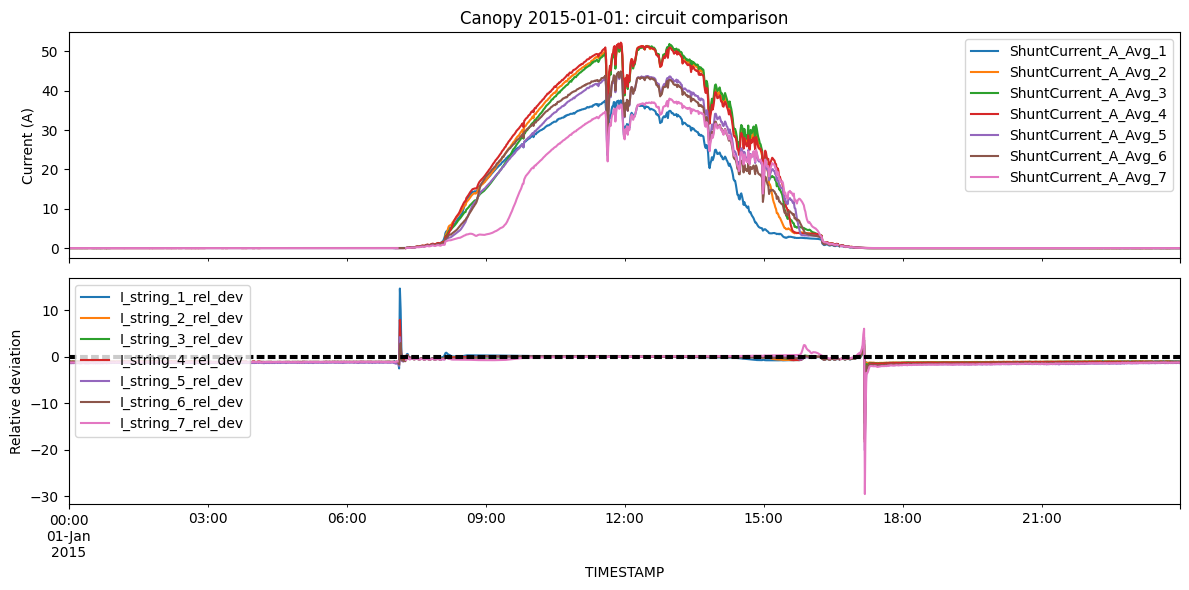

In [42]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
df.loc[PLOT_DAY, string_current_cols].plot(ax=axes[0])
axes[0].set(ylabel="Current (A)", title=f"{site.name.title()} {PLOT_DAY}: circuit comparison")
df.loc[PLOT_DAY, rel_dev_cols].plot(ax=axes[1])
axes[1].axhline(-STRING_REL_DEV_THRESHOLD, color="black", linestyle="--")
axes[1].axhline(STRING_REL_DEV_THRESHOLD, color="black", linestyle="--")
axes[1].set_ylabel("Relative deviation")
plt.tight_layout()
plt.show()


# Inverter Level Faults

Inverter analysis compares DC input, AC output and shunt-measured circuit power, retaining the original distinction between physical indicators and inverter-reported fault codes.

## 1. Inverter Policy and Engineered Features

The configured policy is passed to **both** feature calculation and labeling.

| Setting | Original policy (default here) | Revised policy |
|---|---|---|
| Power shutdown | AC power < 0.05 kW | DC input power < 1 kW |
| Status shutdown | Missing status or status <= 0 | Also status > 5 |
| Minimum DC power for efficiency faults | > 1 kW | > 5 kW |
| Reported active fault | Positive code | Nonzero, nonmissing code |

`inverter_features` generates:

- Raw efficiency $\eta=P_{AC}/P_{DC}$ and efficiency clipped to [0, 1].
- DC discrepancy $P_{string,total}-P_{DC}$, and percentage relative to inverter DC power.
- Loading ratio $P_{AC}/P_{AC,max}$.
- Any active reported fault and active fault count over the six fault-code channels.
- A 5-row rolling mean of clipped efficiency (minimum 3 observations).
- Separate power/status shutdown flags, requiring operating mask 1 and POA at least 100 W/m².

Zero DC input becomes a missing ratio denominator. Raw efficiency above 1 is preserved for inspection; clipping changes only the rolling input. Reported fault codes are diagnostics and do not directly assign the inverter label.


In [43]:
display(pd.Series(asdict(INVERTER_POLICY), name="selected_inverter_policy").to_frame())
df = append_features(df, inverter_features(df, site, policy=INVERTER_POLICY))
inverter_columns = [
    "inv_efficiency", "inv_efficiency_clipped", "inv_efficiency_roll5",
    "DC_power_discrepancy", "DC_power_discrepancy_pct", "inv_loading_ratio",
    "inv_any_fault_reported", "inv_fault_count",
    "inv_shutdown_power_flag", "inv_shutdown_status_flag",
]
display(df[inverter_columns].describe().T)


,selected_inverter_policy
shutdown_column,InvPDC_kW_Avg
shutdown_threshold,1.0
invalid_status_above_five,True
efficiency_min_dc_kw,5.0
fault_flags_nonzero,True


,count,mean,std,min,25%,50%,75%,max
inv_efficiency,264209.0,0.876337,6.521200,0.000000,0.755735,0.883044,0.910135,999.0
inv_efficiency_clipped,264209.0,0.767766,0.256473,0.000000,0.755735,0.883044,0.910135,1.0
inv_efficiency_roll5,264314.0,0.767833,0.253782,0.000000,0.758113,0.881829,0.908880,1.0
DC_power_discrepancy,525235.0,-2.238867,39.053145,-211.557000,-7.380000,0.000000,0.000000,1149.3
DC_power_discrepancy_pct,264209.0,37.595980,1706.251360,-122.055586,-18.493933,-8.653625,-6.047535,148000.0
inv_loading_ratio,525235.0,0.126152,0.260087,-3.842308,0.000000,0.000000,0.195538,1.0
inv_any_fault_reported,525600.0,0.001486,0.038519,0.000000,0.000000,0.000000,0.000000,1.0
inv_fault_count,525600.0,0.008710,0.227538,0.000000,0.000000,0.000000,0.000000,6.0
inv_shutdown_power_flag,525600.0,0.001526,0.039033,0.000000,0.000000,0.000000,0.000000,1.0
inv_shutdown_status_flag,525600.0,0.000537,0.023157,0.000000,0.000000,0.000000,0.000000,1.0


## 2. Inverter Shutdown and Efficiency Fault Labels

`label_inverter` applies the following rules in order:

| Priority | Label | Rule |
|---|---|---|
| 1 | NOT_EVALUABLE | Operating mask = 0 |
| 2 | MISSING_DATA | AC or DC power missing |
| 3 | INVERTER_SHUTDOWN | Either shutdown flag is 1 |
| 4 | INVERTER_EFFICIENCY_FAULT | Evaluable irradiance, status in (0, 5], no shutdown, rolling clipped efficiency < 0.85, DC power above policy minimum, loading ratio > 0.20 |
| Default | NORMAL | No preceding condition matched |

Loading/status guards reduce efficiency detections during low-load/startup behavior. Shutdown flags precede label assignment, but missing-power precedence means a flagged observation can still receive MISSING_DATA.

The helper requires POA >= 100 W/m² for shutdown/efficiency detection but only tests operating mask 0 for its NOT_EVALUABLE rule. An operating-mask 1 observation with low/missing reference-cell POA can therefore reach NORMAL if no other rule matches. This notebook preserves and exposes the script behavior.


In [44]:
# C: Apply the same policy used to calculate the inverter features.
df["label_inverter"] = label_inverter(df, policy=INVERTER_POLICY)
display(label_distribution(df["label_inverter"]))

shutdown_power = df["inv_shutdown_power_flag"].eq(1)
shutdown_status = df["inv_shutdown_status_flag"].eq(1)
shutdown_breakdown = pd.Series({
    "power_based_only": int((shutdown_power & ~shutdown_status).sum()),
    "status_based_only": int((shutdown_status & ~shutdown_power).sum()),
    "both_flags": int((shutdown_power & shutdown_status).sum()),
    "either_flag": int((shutdown_power | shutdown_status).sum()),
    "assigned_shutdown_label": int(df["label_inverter"].eq("INVERTER_SHUTDOWN").sum()),
})
display(shutdown_breakdown.to_frame("observations"))
report_stage("Inverter features and labels", df, checkpoint="inverter")


,count,percent_of_all_rows
label_inverter,,
NOT_EVALUABLE,335254,63.785008
NORMAL,179982,34.243151
INVERTER_EFFICIENCY_FAULT,9560,1.818874
INVERTER_SHUTDOWN,804,0.152968


,observations
power_based_only,522
status_based_only,2
both_flags,280
either_flag,804
assigned_shutdown_label,804


Inverter features and labels: 525,600 rows x 151 columns


## 3. Efficiency, DC Discrepancy and Reported-Fault Cross-Checks

Inspect raw efficiency under evaluable irradiance, normal status and DC input above the policy minimum. Count efficiency values above 1 before interpreting the clipped rolling feature.

DC discrepancy can reflect wiring losses, measurement disagreement or incomplete circuit measurements; it is not automatically a wiring-fault diagnosis. Compare physics-derived shutdown/efficiency detections with reported fault codes. Agreement supports further investigation, while disagreement can reflect timing, different sensitivities or missing measurements. Neither source is treated as ground truth.


In [45]:
evaluable_inv = df["Op_Mask"].eq(1) & df["POA_fused"].ge(100)
normal_status = df["InvOpStatus_Avg"].gt(0) & df["InvOpStatus_Avg"].le(5)
eff_mask = evaluable_inv & normal_status & df["InvPDC_kW_Avg"].gt(INVERTER_POLICY.efficiency_min_dc_kw)
display(df.loc[eff_mask, [
    "inv_efficiency", "inv_efficiency_roll5", "DC_power_discrepancy_pct", "inv_loading_ratio",
]].describe().T)
valid_efficiency = df.loc[eff_mask, "inv_efficiency"].dropna()
above_one = int(valid_efficiency.gt(1).sum())
print(f"Raw efficiency above 1: {above_one:,} of {len(valid_efficiency):,} nonmissing evaluated values")

fault_values = df.loc[:, list(FAULT_FLAG_COLUMNS)]
if INVERTER_POLICY.fault_flags_nonzero:
    active_faults = fault_values.notna() & fault_values.ne(0)
else:
    active_faults = fault_values.gt(0)
display(active_faults.sum().to_frame("active_code_observations"))
display(pd.crosstab(
    df["label_inverter"], df["inv_any_fault_reported"],
    rownames=["physics_label"], colnames=["reported_fault"], margins=True,
))

reported = df["inv_any_fault_reported"].eq(1)
physics_fault = df["label_inverter"].isin(["INVERTER_SHUTDOWN", "INVERTER_EFFICIENCY_FAULT"])
display(pd.Series({
    "physics_fault_and_reported": int((physics_fault & reported).sum()),
    "physics_fault_without_report": int((physics_fault & ~reported).sum()),
    "reported_without_physics_fault_during_evaluable_irradiance": int((reported & ~physics_fault & evaluable_inv).sum()),
}).to_frame("observations"))


,count,mean,std,min,25%,50%,75%,max
inv_efficiency,180953.0,0.878080,0.077031,0.0,0.860100,0.897122,0.914667,3.326867
inv_efficiency_roll5,180929.0,0.877464,0.066402,0.0,0.861445,0.896524,0.913583,1.000000
DC_power_discrepancy_pct,180953.0,-9.803009,7.640852,-100.0,-11.857765,-7.962452,-6.332786,579.393035
inv_loading_ratio,180953.0,0.369633,0.208283,0.0,0.183577,0.340385,0.541154,1.000000


Raw efficiency above 1: 1,493 of 180,953 nonmissing evaluated values


,active_code_observations
InvMainFault_Max,781
InvDriveFault_Max,754
InvVoltageFault_Max,769
InvGridFault_Max,758
InvTempFault_Max,762
InvSystemFault_Max,754


reported_fault,0,1,All
physics_label,,,
INVERTER_EFFICIENCY_FAULT,9560,0,9560
INVERTER_SHUTDOWN,596,208,804
NORMAL,179966,16,179982
NOT_EVALUABLE,334697,557,335254
All,524819,781,525600


,observations
physics_fault_and_reported,208
physics_fault_without_report,10156
reported_without_physics_fault_during_evaluable_irradiance,4


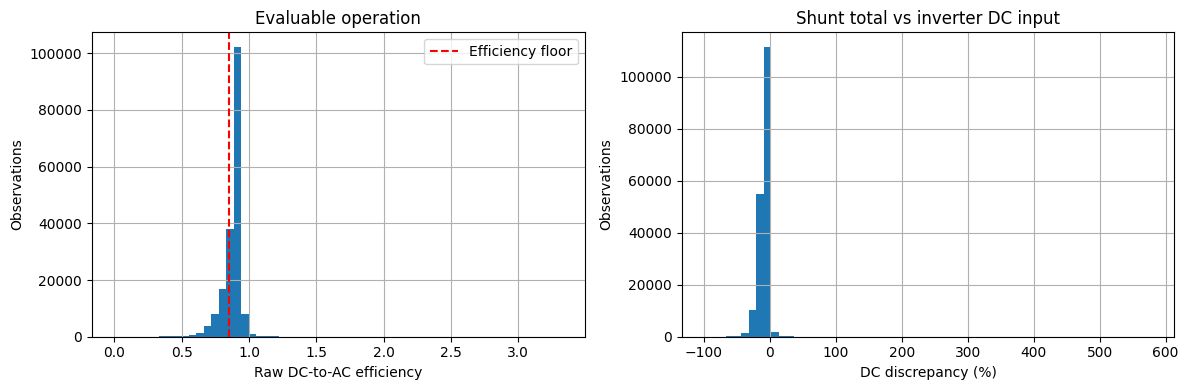

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
valid_efficiency.hist(bins=60, ax=axes[0])
axes[0].axvline(0.85, color="red", linestyle="--", label="Efficiency floor")
axes[0].set(xlabel="Raw DC-to-AC efficiency", ylabel="Observations", title="Evaluable operation")
axes[0].legend()
df.loc[eff_mask, "DC_power_discrepancy_pct"].dropna().hist(bins=60, ax=axes[1])
axes[1].set(xlabel="DC discrepancy (%)", ylabel="Observations", title="Shunt total vs inverter DC input")
plt.tight_layout()
plt.show()


# Final Validation, Label Summaries and Export

The labels remain separate: `label_power`, `label_string` and `label_inverter`. Cross-tabulations show whether detections coincide. This notebook does not combine them into one target or create forecasting labels.

Final checks confirm that the original rows/timestamp sequence were preserved, column names remain unique and every observation has all three labels. The stage audit documents dimensionality changes. These checks establish structural consistency, not fault-label accuracy.


In [47]:
validate_site_year(df, YEAR)
assert len(df) == original_rows, "The pipeline changed the observation count"
assert df.index.equals(original_index), "The pipeline changed timestamps or their order"
assert not df.columns.duplicated().any(), "Duplicate output column names"
label_columns = ["label_power", "label_string", "label_inverter"]
assert df[label_columns].notna().all().all(), "Missing labels in final output"

final_summary = summarize(df)
final_summary.insert(0, "year", YEAR)
final_summary.insert(0, "site", site.name)
stage_audit = pd.DataFrame(stage_records)
display(stage_audit)
display(final_summary)
display(pd.crosstab(df["label_power"], df["label_string"], margins=True))
display(pd.crosstab(df["label_power"], df["label_inverter"], margins=True))
display(df.head())


,stage,rows,columns
0,Raw measurements,525600,101
1,Raw measurements,525600,101
2,Secondary features removed,525600,78
3,Redundant features removed,525600,63
4,Site-specific RTDs removed,525600,59
5,Feature selection complete,525600,59
6,Missingness policy applied,525600,58
7,Missingness policy applied,525600,58
8,Missingness policy applied,525600,58
9,Bounds cleaning complete,525600,58


,site,year,label_type,label,count,percentage
0,canopy,2015,label_power,NOT_EVALUABLE,382385,72.752093
1,canopy,2015,label_power,NORMAL,129373,24.614346
2,canopy,2015,label_power,CRITICAL_UNDERPERFORMANCE,5448,1.036530
3,canopy,2015,label_power,MISSING_DATA,5443,1.035578
4,canopy,2015,label_power,UNDERPERFORMANCE,2170,0.412861
5,canopy,2015,label_power,SEVERE_UNDERPERFORMANCE,658,0.125190
6,canopy,2015,label_power,SUSPICIOUSLY_HIGH,123,0.023402
7,canopy,2015,label_string,NOT_EVALUABLE,382385,72.752093
8,canopy,2015,label_string,NORMAL,132049,25.123478
9,canopy,2015,label_string,STRING_IMBALANCE,10871,2.068303


label_string,MISSING_DATA,NORMAL,NOT_EVALUABLE,OPEN_CIRCUIT_STRING,STRING_IMBALANCE,All
label_power,,,,,,
CRITICAL_UNDERPERFORMANCE,15,6,0,218,5209,5448
MISSING_DATA,3,4678,0,31,731,5443
NORMAL,1,127014,0,20,2338,129373
NOT_EVALUABLE,0,0,382385,0,0,382385
SEVERE_UNDERPERFORMANCE,0,39,0,4,615,658
SUSPICIOUSLY_HIGH,0,58,0,0,65,123
UNDERPERFORMANCE,0,254,0,3,1913,2170
All,19,132049,382385,276,10871,525600


label_inverter,INVERTER_EFFICIENCY_FAULT,INVERTER_SHUTDOWN,NORMAL,NOT_EVALUABLE,All
label_power,,,,,
CRITICAL_UNDERPERFORMANCE,2,253,5193,0,5448
MISSING_DATA,606,36,4801,0,5443
NORMAL,8820,2,120551,0,129373
NOT_EVALUABLE,1,494,46636,335254,382385
SEVERE_UNDERPERFORMANCE,16,9,633,0,658
SUSPICIOUSLY_HIGH,4,0,119,0,123
UNDERPERFORMANCE,111,10,2049,0,2170
All,9560,804,179982,335254,525600


,Pyra1_Wm2_Avg,Pyra2_Wm2_Avg,Pyra3_Wm2_Avg,RefCell1_Wm2_Avg,RefCell2_Wm2_Avg,AmbTemp_C_Avg,InvVDVoltage_V_Avg,InvVa_Avg,InvVb_Avg,InvVc_Avg,...,inv_efficiency_clipped,DC_power_discrepancy,DC_power_discrepancy_pct,inv_loading_ratio,inv_any_fault_reported,inv_fault_count,inv_efficiency_roll5,inv_shutdown_power_flag,inv_shutdown_status_flag,label_inverter
TIMESTAMP,,,,,,,,,,,,,,,,,,,,,
2015-01-01 00:00:00-05:00,-4.433096,-8.782201,-4.542599,-0.548,-0.040,-2.229,11.75,277.4,276.5,278.1,...,NaN,0.0,NaN,0.0,0,0,NaN,0,0,NOT_EVALUABLE
2015-01-01 00:01:00-05:00,-4.433096,-8.782201,-4.542599,-0.548,-0.040,-2.099,11.69,277.4,276.5,278.2,...,NaN,0.0,NaN,0.0,0,0,NaN,0,0,NOT_EVALUABLE
2015-01-01 00:02:00-05:00,-4.433096,-8.782201,-4.542599,-0.550,-0.041,-2.185,11.62,277.4,276.5,278.2,...,NaN,0.0,NaN,0.0,0,0,NaN,0,0,NOT_EVALUABLE
2015-01-01 00:03:00-05:00,-4.433096,-8.977362,-4.542599,-0.547,-0.038,-2.261,11.57,277.4,276.5,278.2,...,NaN,0.0,NaN,0.0,0,0,NaN,0,0,NOT_EVALUABLE
2015-01-01 00:04:00-05:00,-4.669528,-9.270102,-4.542599,-0.545,-0.036,-2.391,11.49,277.3,276.5,278.2,...,NaN,0.0,NaN,0.0,0,0,NaN,0,0,NOT_EVALUABLE


## Save the Labeled Dataset and Methodology Record

The final CSV contains retained measurements, engineered features, three labels and one TIMESTAMP index column. Companion files save label distributions, the stage audit, and a methodology record containing configuration, policy, annual string baselines and repository commit.

`OVERWRITE_FINAL = True` permits replacement of these final files, including datasets created by the batch runner. The walkthrough does not reproduce every original intermediate filename: optional checkpoints use the shared `save_stage` convention instead.

After running, use the actual tables/plots to write the selected site/year findings. Discuss sampling gaps, missing-data precedence, model assumptions, baseline fit period and heuristic thresholds alongside the observed distributions.


In [48]:
export_paths = [final_path, summary_path, audit_path, metadata_path]
existing = [str(path) for path in export_paths if path.exists()]
if existing and not OVERWRITE_FINAL:
    raise FileExistsError(
        "Outputs already exist; set OVERWRITE_FINAL = True to replace them:\n"
        + "\n".join(existing)
    )

repo_commit = subprocess.run(
    ["git", "-C", str(repo_path), "rev-parse", "HEAD"],
    check=True, capture_output=True, text=True,
).stdout.strip()
methodology = {
    "site": asdict(site),
    "year": YEAR,
    "repository_commit": repo_commit,
    "inverter_policy": asdict(INVERTER_POLICY),
    "string_baselines": INORM_BASELINE,
    "baseline_fit_period": "Full selected year; evaluable observations",
    "performance_rounding_decimals": 3,
    "coverage": {key: int(value) for key, value in coverage.items()},
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "exported_utc": pd.Timestamp.now(tz="UTC").isoformat(),
}
output_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(final_path, index=True, index_label="TIMESTAMP")
final_summary.to_csv(summary_path, index=False)
stage_audit.to_csv(audit_path, index=False)
metadata_path.write_text(json.dumps(methodology, indent=2), encoding="utf-8")
for path in export_paths:
    print(f"Saved: {path}")


Saved: /content/drive/MyDrive/NIST_Labels/canopy_2015.csv
Saved: /content/drive/MyDrive/NIST_Labels/canopy_2015_label_summary.csv
Saved: /content/drive/MyDrive/NIST_Labels/canopy_2015_stage_audit.csv
Saved: /content/drive/MyDrive/NIST_Labels/canopy_2015_methodology.json
